# Préparation des données pour le Machine Learning

Ce notebook guide étape par étape le processus de nettoyage des données des arbres de Grenoble pour prédire l'année de plantation.

## Objectif
Préparer les données pour entraîner un modèle de Machine Learning qui pourra prédire l'année de plantation des arbres manquantes.

## Plan du notebook
1. Import des bibliothèques et chargement des données
2. Exploration initiale des données
3. Nettoyage des données
4. Sauvegarder en pikle les données

## 1. Import des bibliothèques et chargement des données

Nous utilisons plusieurs bibliothèques Python essentielles pour l'analyse de données :
- pandas : pour la manipulation des données
- numpy : pour les calculs numériques
- matplotlib et seaborn : pour la visualisation
- sklearn : pour la préparation des données pour le ML

In [1]:
# Les libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Chargement des données
df = pd.read_csv('data/arbres_grenoble_epsg4326.csv', sep=',', encoding='utf-8')

# Affichage des premières lignes
print('Aperçu des données :')
display(df.head())

# Informations sur le dataset
print('\nInformations sur le dataset :')
display(df.info())

Aperçu des données :


,elem_point_id,code,nom,genre,genre_desc,categorie,categorie_desc,sous_categorie,sous_categorie_desc,code_parent,...,diametrearbre,causeabattage,collectivite,stationmetro,hauteurarbre,portarbre,structure,forme,typenature,geo_point_2d
0,34835,ESP36318,AR36318,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167098421885385,5.740131798404362"
1,34836,ESP36319,AR36319,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16710682038838,5.740199792549315"
2,34837,ESP36320,AR36320,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167115270975415,5.740265608803635"
3,34838,ESP36321,AR36321,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16712715617142,5.740349032579623"
4,34839,ESP36322,AR36322,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167144245872265,5.740471081600832"



Informations sur le dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   elem_point_id          31670 non-null  int64  
 1   code                   31670 non-null  object 
 2   nom                    31670 non-null  object 
 3   genre                  31670 non-null  object 
 4   genre_desc             31670 non-null  object 
 5   categorie              31670 non-null  object 
 6   categorie_desc         31670 non-null  object 
 7   sous_categorie         31670 non-null  object 
 8   sous_categorie_desc    31670 non-null  object 
 9   code_parent            31670 non-null  object 
 10  code_parent_desc       31670 non-null  object 
 11  adr_secteur            31670 non-null  int64  
 12  bien_reference         31670 non-null  object 
 13  genre_bota             30859 non-null  object 
 14  espece                 

None

## 2. Exploration initiale des données

Avant de commencer le nettoyage, il est crucial de comprendre nos données :
- Quelles sont les colonnes disponibles ?
- Quels types de données avons-nous ?
- Y a-t-il des valeurs manquantes ?

In [3]:
# Statistiques descriptives
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
elem_point_id,31670.0,NaN,NaN,NaN,21194.586391,13384.342841,1.0,9947.25,20019.5,30761.75,48387.0
code,31670,31670,ESP36318,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nom,31670,31670,AR36318,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,31670,1,VEG,31670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre_desc,31670,1,VEGETATION,31670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categorie,31670,1,ESP01,31670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categorie_desc,31670,1,Arbre,31670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sous_categorie,31670,4,ESP174,15222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sous_categorie_desc,31670,4,Arbre d'espaces ouverts,15222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
code_parent,31670,1505,ESP995,369,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Analyse des valeurs manquantes
missing = pd.DataFrame({
    'nb_manquantes': df.isna().sum(),
    'pct_manquantes': (df.isna().mean() * 100).round(2)
}).sort_values('pct_manquantes', ascending=False)
missing[missing['nb_manquantes'] > 0]

,nb_manquantes,pct_manquantes
courrier,31670,100.00
anneeabattage,31670,100.00
causeabattage,31670,100.00
diametrearbre,31670,100.00
essouchement,31670,100.00
equipe,31670,100.00
identifiantplu,31083,98.15
intituleprotectionplu,31083,98.15
stationmetro,29788,94.06
traitementchenilles,29604,93.48


### Visualisation des valeurs manquantes

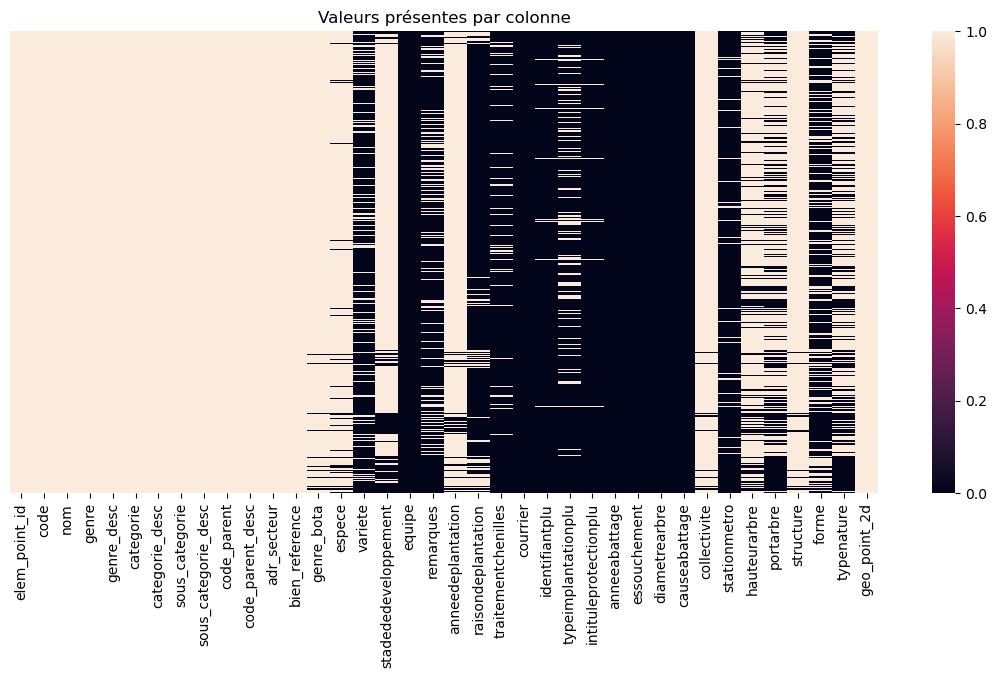

In [5]:
# Création d'une heatmap des valeurs manquantes
plt.figure(figsize=(14, 6))
sns.heatmap(df.notna(),  yticklabels=False)
plt.title("Valeurs présentes par colonne")
plt.show()

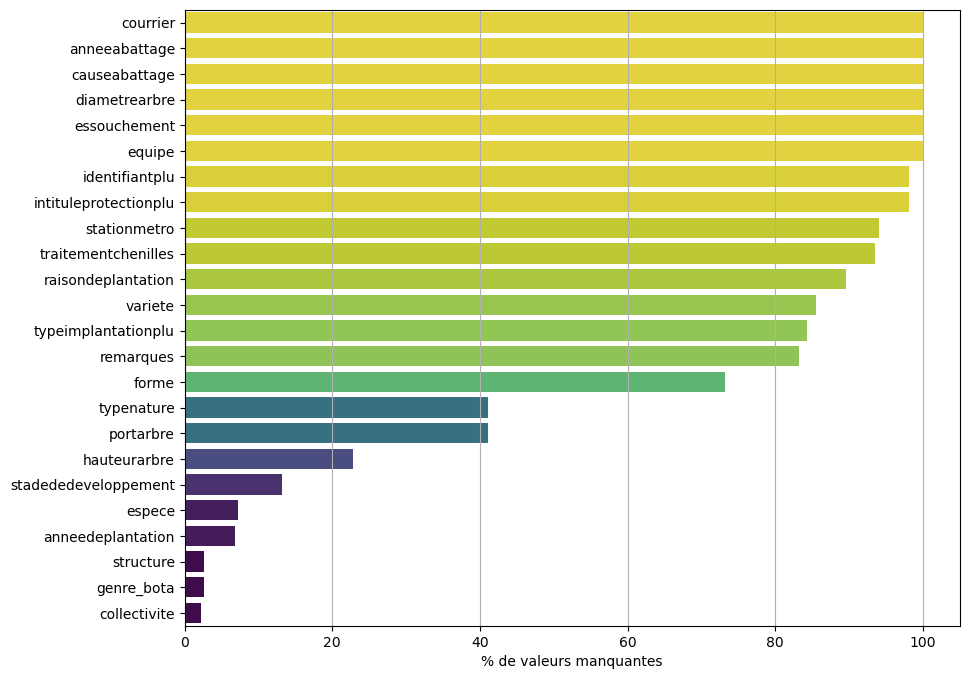

In [6]:
# Création avec des bars hue
m = missing[missing['nb_manquantes'] > 0].reset_index()
plt.figure(figsize=(10, 8))
sns.barplot(data=m, x='pct_manquantes', y='index', hue='pct_manquantes', palette='viridis', legend=False)
plt.xlabel("% de valeurs manquantes")
plt.ylabel("")
plt.grid(axis='x')
plt.show()

## 3. Nettoyage des données
1. Suppression des lignes sans année de plantation
2. Supprimer les colonnes non pertinentes pour la prédiction
3. Extraire les coordonnées géographiques
### 3.1 Après l'analyse initiale, nous allons :


In [7]:
# 3.1 Suppression des lignes sans année de plantation
df = df.dropna(subset = "anneedeplantation")
df

,elem_point_id,code,nom,genre,genre_desc,categorie,categorie_desc,sous_categorie,sous_categorie_desc,code_parent,...,diametrearbre,causeabattage,collectivite,stationmetro,hauteurarbre,portarbre,structure,forme,typenature,geo_point_2d
0,34835,ESP36318,AR36318,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167098421885385,5.740131798404362"
1,34836,ESP36319,AR36319,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16710682038838,5.740199792549315"
2,34837,ESP36320,AR36320,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167115270975415,5.740265608803635"
3,34838,ESP36321,AR36321,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16712715617142,5.740349032579623"
4,34839,ESP36322,AR36322,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167144245872265,5.740471081600832"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31662,44732,ESP40741,AR40741,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP479,...,NaN,NaN,Grenoble Alpes Métropole,NaN,Moins de 10 m,NaN,Métropole de Grenoble,Tige,NaN,"45.19086602812676,5.719433884185321"
31663,44733,ESP40742,AR40742,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP479,...,NaN,NaN,Grenoble Alpes Métropole,NaN,Moins de 10 m,NaN,Métropole de Grenoble,Tige,NaN,"45.19087719105167,5.719507440014668"
31664,44734,ESP40743,AR40743,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP479,...,NaN,NaN,Grenoble Alpes Métropole,NaN,Moins de 10 m,NaN,Métropole de Grenoble,Tige,NaN,"45.19089795904305,5.719652195732456"
31665,44741,ESP40744,AR40744,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP479,...,NaN,NaN,Grenoble Alpes Métropole,NaN,Moins de 10 m,NaN,Métropole de Grenoble,Tige,NaN,"45.19130940286065,5.721605325148501"


### 🔍 3.2 Nettoyage des colonnes inutiles

Nous allons :

- Supprimer les colonnes contenant plus de **40 % de valeurs manquantes**
- Supprimer les colonnes **trop spécifiques** (identifiants uniques par exemple), qui n’apportent pas d'information utile pour l'apprentissage automatique
- Supprimer les colonnes qui contiennent la même information ne sont pas utile

In [8]:
# 2 Supprimer les colonnes trop spécifiques, par exemple la colonne elem_point_id
# df = df.drop([elem_point_id])
# Supprimer les colonnes contenant plus de 40 % de valeurs manquantes
df = df.loc[:, df.isna().mean() <= 0.4]
cols_a_supprimer = [
    "elem_point_id", "code", "nom", "bien_reference","categorie_desc",
    "genre", "categorie", "sous_categorie", "code_parent",
    "genre_desc",   # constante
    "structure",    # redondante avec collectivite
]
df = df.drop(columns=cols_a_supprimer, errors="ignore")

In [9]:
# 3. Extraire les coordonnées géographiques, séparer latitude et longitude
df[['latitude', 'longitude']] = (
    df['geo_point_2d']
    .str.split(',', expand=True)
    .astype(float)
)
df = df.drop(columns='geo_point_2d')

In [12]:
df.nunique()

sous_categorie_desc         4
code_parent_desc         1462
adr_secteur                11
genre_bota                118
espece                    282
stadededeveloppement        3
anneedeplantation          68
collectivite                2
hauteurarbre                3
portarbre                   6
typenature                  6
latitude                29526
longitude               29526
dtype: int64

## 4. Sauvegarde des données nettoyées en pikle


In [10]:
# Sauvegarde des données
df.to_pickle('data/arbres_clean.pkl')

In [11]:
df

,sous_categorie_desc,code_parent_desc,adr_secteur,genre_bota,espece,stadededeveloppement,anneedeplantation,collectivite,hauteurarbre,portarbre,typenature,latitude,longitude
0,Arbre de voirie,Av La Bruyère Helbronner au Sq,5,Prunus,serrulata,Arbre jeune,2015.0,Grenoble Alpes Métropole,NaN,NaN,NaN,45.167098,5.740132
1,Arbre de voirie,Av La Bruyère Helbronner au Sq,5,Prunus,serrulata,Arbre jeune,2015.0,Grenoble Alpes Métropole,NaN,NaN,NaN,45.167107,5.740200
2,Arbre de voirie,Av La Bruyère Helbronner au Sq,5,Prunus,serrulata,Arbre jeune,2015.0,Grenoble Alpes Métropole,NaN,NaN,NaN,45.167115,5.740266
3,Arbre de voirie,Av La Bruyère Helbronner au Sq,5,Prunus,serrulata,Arbre jeune,2015.0,Grenoble Alpes Métropole,NaN,NaN,NaN,45.167127,5.740349
4,Arbre de voirie,Av La Bruyère Helbronner au Sq,5,Prunus,serrulata,Arbre jeune,2015.0,Grenoble Alpes Métropole,NaN,NaN,NaN,45.167144,5.740471
...,...,...,...,...,...,...,...,...,...,...,...,...,...
31662,Arbre de voirie,A F Viallet la Gare à Jaures,1,Koelreuteria,paniculata,NaN,2018.0,Grenoble Alpes Métropole,Moins de 10 m,NaN,NaN,45.190866,5.719434
31663,Arbre de voirie,A F Viallet la Gare à Jaures,1,Pyrus,calleryana,NaN,2018.0,Grenoble Alpes Métropole,Moins de 10 m,NaN,NaN,45.190877,5.719507
31664,Arbre de voirie,A F Viallet la Gare à Jaures,1,Acer,rubrum,NaN,2018.0,Grenoble Alpes Métropole,Moins de 10 m,NaN,NaN,45.190898,5.719652
31665,Arbre de voirie,A F Viallet la Gare à Jaures,1,Acer,rubrum,NaN,2018.0,Grenoble Alpes Métropole,Moins de 10 m,NaN,NaN,45.191309,5.721605


## Conclusion

Nous avons effectué plusieurs étapes de nettoyage importantes :
1. Suppression des colonnes non pertinentes ou avec trop de valeurs manquantes
2. Extraction des coordonnées géographiques

Les données sont maintenant prêtes pour la suite du projet